# output.ipynb — Mục 4.2.2: Suy luận Bayesian CPT và ANFIS rule học được
## Thực nghiệm 1 — A2_soft_exp1

Notebook này đọc trực tiếp artifact JSON của thực nghiệm 1 (**không chạy lại training**) và sinh các biểu đồ phục vụ mục 4.2 của khóa luận:
- Cấu trúc Bayesian Network
- CPT heatmap (log-likelihood ratio)
- Raw CPT grouped bars
- Sample BN inference trace
- ANFIS rule importance heatmap

---
## Phần 1 — Load experiment artifacts

In [12]:
"""
Phần 1: Load experiment artifacts từ folder A2_soft_exp1.
Không chạy lại training. Chỉ đọc JSON artifact đã có sẵn.
"""
import json
import re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

# ---------------------------------------------------------------
# Đường dẫn artifact — dùng pathlib để tương thích Kaggle/Linux
# ---------------------------------------------------------------
# Notebook này nằm ở gốc project; artifact nằm trong:
#   artifacts/A2_soft_exp1/
# Nếu chạy trên Kaggle, sửa ROOT cho phù hợp.
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

EXP_NAME = "A2_soft_exp1"

# Updated path: no double nesting (fixed May 20, 2026)
EXP_DIR = ROOT / "artifacts" / EXP_NAME

REQUIRED_FILES = {
    "bn_details": EXP_DIR / "bn_details.json",
    "anfis_rules": EXP_DIR / "anfis_rules.json",
}

# Kiểm tra file tồn tại — báo lỗi rõ ràng thay vì silent fail
missing = [name for name, path in REQUIRED_FILES.items() if not path.exists()]
if missing:
    raise FileNotFoundError(
        f"[ERROR] Các file artifact sau không tìm thấy trong {EXP_DIR}:\n"
        + "\n".join(f"  - {name}: {REQUIRED_FILES[name]}" for name in missing)
    )

# Load JSON
with open(REQUIRED_FILES["bn_details"], encoding="utf-8") as f:
    bn_details = json.load(f)

with open(REQUIRED_FILES["anfis_rules"], encoding="utf-8") as f:
    anfis_rules = json.load(f)

# ---------------------------------------------------------------
# In summary
# ---------------------------------------------------------------
cfg = bn_details["configuration"]
metrics = bn_details["test_metrics"]
bn_struct = bn_details["bn_structure"]

print("=" * 60)
print(f"Experiment  : {bn_details['experiment']}")
print(f"Threshold   : {bn_details['threshold']}")
print(f"Test metrics: acc={metrics['acc']:.4f}  bal_acc={metrics['bal_acc']:.4f}"
      f"  macro_f1={metrics['macro_f1']:.4f}  AUC={metrics['auc']:.4f}")
print(f"BN root     : {bn_struct['root']}  states={bn_struct['root_states']}")
print(f"Evidence    : {bn_struct['evidence_nodes']}")
print(f"n_bins      : {bn_struct['n_bins']}  bin_names={bn_struct['bin_names']}")
print("=" * 60)

# Tạo thư mục output
FIG_DIR = EXP_DIR / "figures_4_2"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Output dir  : {FIG_DIR}")

Experiment  : A2_soft_exp1
Threshold   : 0.55
Test metrics: acc=0.7513  bal_acc=0.7519  macro_f1=0.7511  AUC=0.7734
BN root     : CL  states=['rest', 'task']
Evidence    : ['Temp', 'HR', 'GSR', 'RR']
n_bins      : 5  bin_names=['very_low', 'low', 'med', 'high', 'very_high']
Output dir  : D:\SGU(1)\official\4-1\KLTN\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2


---
## Phần 2 — Figure: Cấu trúc Bayesian Network

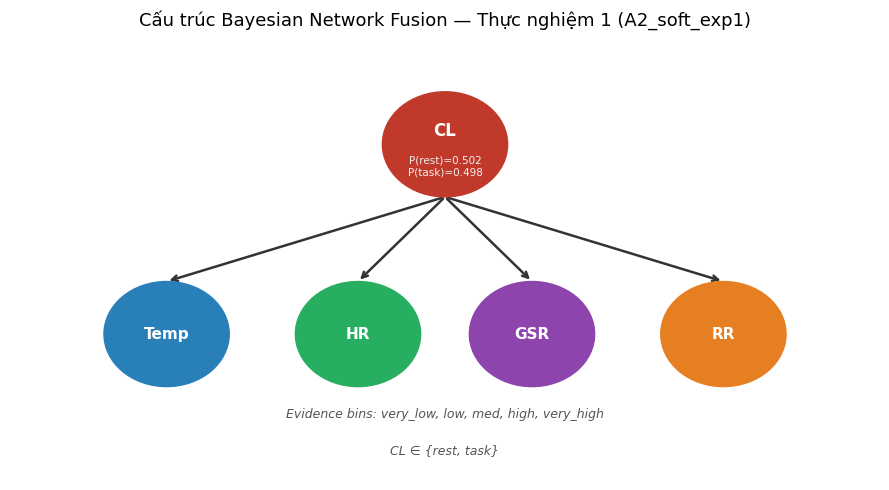

[saved] D:\SGU(1)\official\4-1\KLTN\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_bn_structure.png


In [13]:
"""
Phần 2: Vẽ sơ đồ cấu trúc Bayesian Network.
Dùng matplotlib patches — không cần pyAgrum, chạy được trên Kaggle.
"""

prior = bn_details["prior"]
evidence_nodes = bn_struct["evidence_nodes"]   # ['Temp', 'HR', 'GSR', 'RR']
bin_names = bn_struct["bin_names"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

# Hàm helper vẽ node tròn với text
def draw_node(ax, cx, cy, label, sub="", color="#4C72B0", fontsize=11):
    circle = plt.Circle((cx, cy), 0.72, color=color, zorder=3)
    ax.add_patch(circle)
    ax.text(cx, cy + (0.18 if sub else 0), label,
            ha="center", va="center", fontsize=fontsize,
            fontweight="bold", color="white", zorder=4)
    if sub:
        ax.text(cx, cy - 0.3, sub, ha="center", va="center",
                fontsize=7.5, color="#f0f0f0", zorder=4)

# Hàm helper vẽ mũi tên
def draw_arrow(ax, x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", lw=1.8, color="#333333"),
                zorder=2)

# ----- Root node CL -----
cl_x, cl_y = 5.0, 4.6
draw_node(ax, cl_x, cl_y, "CL",
          f"P(rest)={prior['rest']:.3f}\nP(task)={prior['task']:.3f}",
          color="#c0392b", fontsize=12)

# ----- Evidence nodes -----
ev_positions = {
    "Temp": (1.8, 2.0),
    "HR":   (4.0, 2.0),
    "GSR":  (6.0, 2.0),
    "RR":   (8.2, 2.0),
}
ev_colors = {"Temp": "#2980b9", "HR": "#27ae60", "GSR": "#8e44ad", "RR": "#e67e22"}

for sig, (ex, ey) in ev_positions.items():
    draw_node(ax, ex, ey, sig, color=ev_colors[sig], fontsize=11)
    # Vẽ mũi tên từ CL xuống evidence
    draw_arrow(ax, cl_x, cl_y - 0.72, ex, ey + 0.72)

# ----- Chú thích bins -----
bins_str = ", ".join(bin_names)
ax.text(5.0, 0.9, f"Evidence bins: {bins_str}",
        ha="center", va="center", fontsize=9, color="#555555",
        style="italic")
ax.text(5.0, 0.4, "CL ∈ {rest, task}",
        ha="center", va="center", fontsize=9, color="#555555",
        style="italic")

ax.set_title("Cấu trúc Bayesian Network Fusion — Thực nghiệm 1 (A2_soft_exp1)",
             fontsize=13, pad=12)

fig.tight_layout()
out_path = FIG_DIR / "fig_bn_structure.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {out_path}")

---
## Phần 3 — Figure: CPT Log-Likelihood Ratio Heatmap

[saved] D:\SGU(1)\official\4-1\KLTN\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\cpt_log_likelihood_ratio.csv
Bin     very_low     low     med    high  very_high
Signal                                             
Temp     -0.0567 -0.1346 -0.0251  0.1004     0.1156
HR       -0.6226 -0.2150  0.1004  0.0376     0.7055
GSR      -0.4875 -0.0567  0.0692  0.1639     0.3053
RR       -1.3363 -0.4422  0.1639  0.4876     1.0427


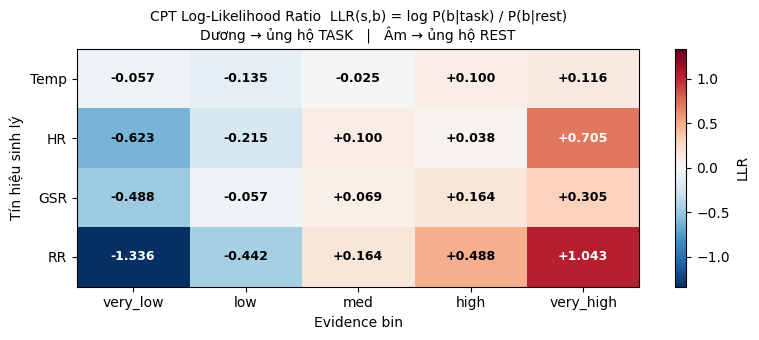

[saved] D:\SGU(1)\official\4-1\KLTN\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_cpt_llr_heatmap.png


In [14]:
"""
Phần 3: CPT Log-Likelihood Ratio heatmap.
LLR(s, b) = log( P(E_s=b | task) / P(E_s=b | rest) )
- Giá trị dương: bin b ủng hộ lớp TASK
- Giá trị âm: bin b ủng hộ lớp REST
"""
cpt = bn_details["cpt_tables"]   # dict: signal -> {rest: {bin: p}, task: {bin: p}}
signals = evidence_nodes          # ['Temp', 'HR', 'GSR', 'RR']

# Tính LLR cho mỗi (signal, bin)
llr_data = {}
for sig in signals:
    llr_data[sig] = {}
    for b in bin_names:
        p_task = cpt[sig]["task"][b]
        p_rest = cpt[sig]["rest"][b]
        # Clip tránh log(0)
        llr_data[sig][b] = np.log(np.maximum(p_task, 1e-9) / np.maximum(p_rest, 1e-9))

# Tạo DataFrame — hàng: signal, cột: bin
df_llr = pd.DataFrame(llr_data, index=bin_names).T  # (n_signals, n_bins)
df_llr.index.name = "Signal"
df_llr.columns.name = "Bin"

# Lưu CSV
csv_path = FIG_DIR / "cpt_log_likelihood_ratio.csv"
df_llr.to_csv(csv_path)
print(f"[saved] {csv_path}")
print(df_llr.round(4))

# ---- Vẽ heatmap bằng matplotlib imshow ----
fig, ax = plt.subplots(figsize=(8, 3.5))
mat = df_llr.values.astype(float)    # (4, 5)
vmax = np.abs(mat).max()

im = ax.imshow(mat, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")

# Trục
ax.set_xticks(range(len(bin_names)))
ax.set_xticklabels(bin_names, fontsize=10)
ax.set_yticks(range(len(signals)))
ax.set_yticklabels(signals, fontsize=10)
ax.set_xlabel("Evidence bin", fontsize=10)
ax.set_ylabel("Tín hiệu sinh lý", fontsize=10)
ax.set_title("CPT Log-Likelihood Ratio  LLR(s,b) = log P(b|task) / P(b|rest)\n"
             "Dương → ủng hộ TASK   |   Âm → ủng hộ REST", fontsize=10)

# Annotate giá trị
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        val = mat[i, j]
        color = "white" if abs(val) > 0.5 * vmax else "black"
        ax.text(j, i, f"{val:+.3f}", ha="center", va="center",
                fontsize=9, color=color, fontweight="bold")

plt.colorbar(im, ax=ax, label="LLR")
fig.tight_layout()
out_path = FIG_DIR / "fig_cpt_llr_heatmap.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {out_path}")

---
## Phần 4 — Figure: Raw CPT Grouped Bars (mỗi tín hiệu một figure)

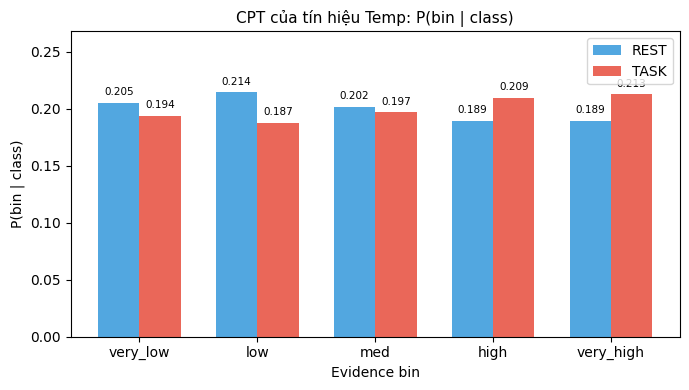

[saved] D:\SGU(1)\official\4-1\KLTN\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_cpt_Temp.png


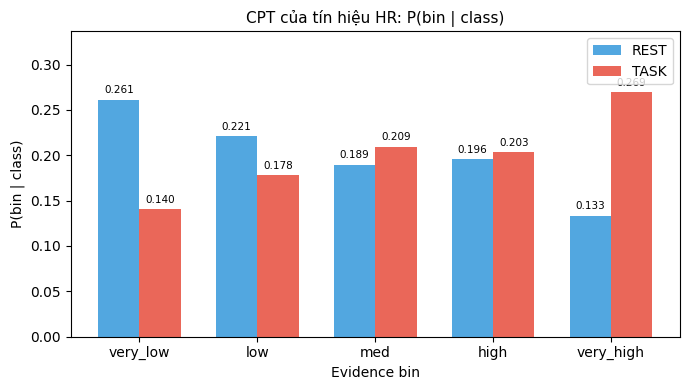

[saved] D:\SGU(1)\official\4-1\KLTN\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_cpt_HR.png


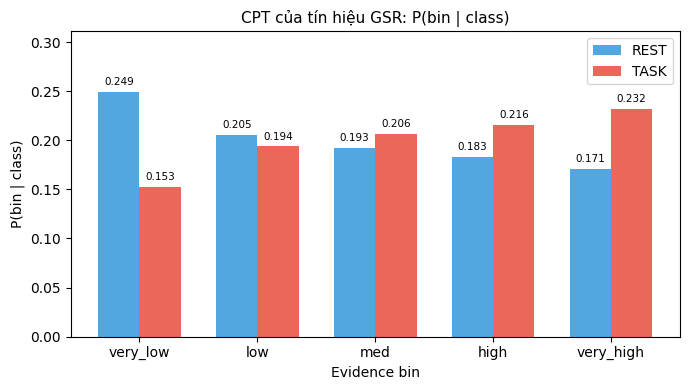

[saved] D:\SGU(1)\official\4-1\KLTN\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_cpt_GSR.png


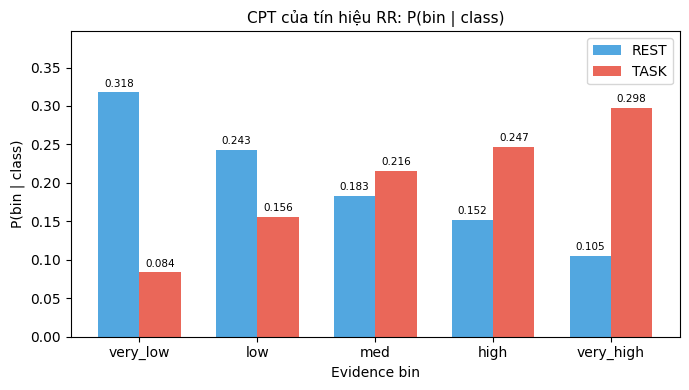

[saved] D:\SGU(1)\official\4-1\KLTN\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_cpt_RR.png


In [15]:
"""
Phần 4: Grouped bar chart P(bin | class) cho mỗi tín hiệu.
Mỗi hình là một tín hiệu với hai nhóm bar: rest và task.
"""
bar_width = 0.35
x = np.arange(len(bin_names))

for sig in signals:
    p_rest = np.array([cpt[sig]["rest"][b] for b in bin_names])
    p_task = np.array([cpt[sig]["task"][b] for b in bin_names])

    fig, ax = plt.subplots(figsize=(7, 4))

    bars_rest = ax.bar(x - bar_width / 2, p_rest, bar_width,
                       label="REST", color="#3498db", alpha=0.85)
    bars_task = ax.bar(x + bar_width / 2, p_task, bar_width,
                       label="TASK", color="#e74c3c", alpha=0.85)

    # Annotate giá trị xác suất lên bar
    for bar in bars_rest:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.005,
                f"{h:.3f}", ha="center", va="bottom", fontsize=7.5)
    for bar in bars_task:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.005,
                f"{h:.3f}", ha="center", va="bottom", fontsize=7.5)

    ax.set_xticks(x)
    ax.set_xticklabels(bin_names, fontsize=10)
    ax.set_ylim(0, max(p_rest.max(), p_task.max()) * 1.25)
    ax.set_xlabel("Evidence bin", fontsize=10)
    ax.set_ylabel("P(bin | class)", fontsize=10)
    ax.set_title(f"CPT của tín hiệu {sig}: P(bin | class)", fontsize=11)
    ax.legend(fontsize=10)

    fig.tight_layout()
    out_path = FIG_DIR / f"fig_cpt_{sig}.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"[saved] {out_path}")

---
## Phần 5 — Figure: Sample BN Inference Trace

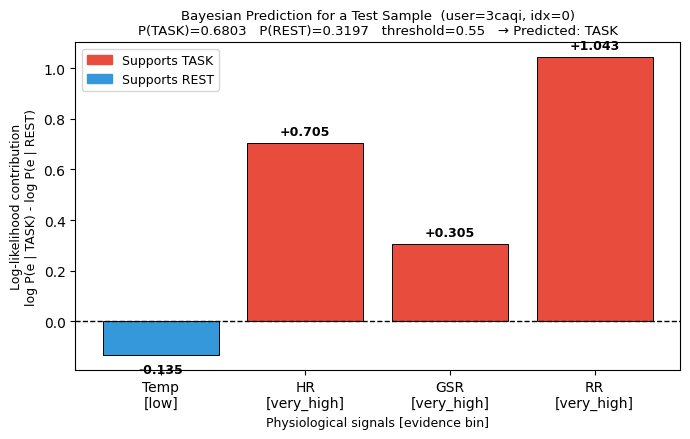

[saved] D:\SGU(1)\official\4-1\KLTN\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_sample_bayesian_prediction.png
[saved] D:\SGU(1)\official\4-1\KLTN\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\sample_bn_inference_trace.csv

Posterior source : stored (predict_proba)
Sample index     : 0
User ID          : 3caqi
Final P(TASK)    : 0.6803
Final P(REST)    : 0.3197
Threshold        : 0.5500
Predicted        : TASK

Signal Evidence_bin  logLL_REST  logLL_TASK  Contribution  sample_index user_id  final_p_task  final_p_rest  threshold predicted
  Temp          low   -1.539924   -1.674502     -0.134578             0   3caqi      0.680279      0.319721       0.55      TASK
    HR    very_high   -2.017253   -1.311961      0.705292             0   3caqi      0.680279      0.319721       0.55      TASK
   GSR    very_high   -1.768557   -1.463192      0.305364             0   3caqi      0.680279      0.319721       

In [16]:
"""
Figure 7 — Sample BN Inference Trace (final posterior, consistent with Streamlit).

For each physiological signal s:
  contribution_s = log P(e_s | TASK) - log P(e_s | REST)

Title uses the final soft-evidence posterior from predict_proba (same as Streamlit),
NOT the hard-bin posterior_task from explain_sample.

Priority for final posterior (best available source):
  1. trace["final_posterior_task"]  — stored by bn_dashboard since May 2026
  2. Recomputed from trace["anfis_probs"] + bn_structure["bin_mids/sigmas"]
  3. Hard-bin fallback (legacy) — shows warning
"""

trace      = bn_details["sample_inference_trace"]
ev_bins    = trace["evidence_bins"]
threshold  = bn_details["threshold"]
log_ll     = trace["log_likelihoods"]
cpt        = bn_details["cpt_tables"]
prior      = bn_details["prior"]
sw         = bn_details.get("signal_weights", {s: 1.0 for s in signals})
bn_struct  = bn_details["bn_structure"]

sample_idx = trace.get("sample_index", 0)
user_id    = trace.get("user_id", "unknown")

# ---------------------------------------------------------------
# Resolve final posterior — three-tier priority
# ---------------------------------------------------------------

def _soft_posterior_from_json(anfis_probs, cpt, bin_names, prior, weights, bin_mids, bin_sigmas):
    """Reproduce predict_proba (soft-evidence) entirely from JSON data."""
    log_p = np.array([np.log(prior["rest"] + 1e-10), np.log(prior["task"] + 1e-10)])
    for sig in anfis_probs:
        p_val   = anfis_probs[sig]
        mids    = np.array(bin_mids[sig])
        sigma   = bin_sigmas[sig]
        w       = weights.get(sig, 1.0)
        # Gaussian kernel membership over bin midpoints
        mem = np.exp(-0.5 * ((p_val - mids) / (sigma + 1e-10)) ** 2)
        mem = mem / (mem.sum() + 1e-10)
        for c_idx, cls in enumerate(["rest", "task"]):
            cpt_vals = np.array([cpt[sig][cls][b] for b in bin_names])
            p_ev = float(np.dot(mem, cpt_vals))
            log_p[c_idx] += w * np.log(p_ev + 1e-10)
    log_p -= log_p.max()
    p = np.exp(log_p)
    p /= p.sum()
    return float(p[1])  # P(task)

if "final_posterior_task" in trace:
    # Best: stored directly by bn_dashboard (bn.predict_proba call)
    post_task_final = trace["final_posterior_task"]
    _source = "stored (predict_proba)"
elif ("anfis_probs" in trace
      and bn_struct.get("bin_mids") is not None
      and bn_struct.get("bin_sigmas") is not None):
    # Good: recompute soft posterior from stored ANFIS probs + bin params
    post_task_final = _soft_posterior_from_json(
        trace["anfis_probs"], cpt, bn_struct["bin_names"],
        prior, sw, bn_struct["bin_mids"], bn_struct["bin_sigmas"],
    )
    _source = "recomputed (soft, from anfis_probs+bin_mids)"
else:
    # Fallback: hard-bin posterior (WILL NOT match Streamlit for soft BN)
    post_task_final = trace["posterior_task"]
    _source = "FALLBACK hard-bin — re-run main.py to get correct value"
    
    print(f"[WARN] Using hard-bin posterior ({post_task_final:.4f}). "
          f"Re-run cell 1 of main.ipynb then reload artifacts to get the "
          f"soft-evidence posterior matching Streamlit.")

post_rest_final = 1.0 - post_task_final
predicted = "TASK" if post_task_final >= threshold else "REST"

# contribution_s = logLL_TASK(s) - logLL_REST(s)  (hard-bin, for bar chart)
contributions = {sig: log_ll["1"][sig] - log_ll["0"][sig] for sig in signals}

# ---------------------------------------------------------------
# Build figure
# ---------------------------------------------------------------
labels = [f"{sig}\n[{ev_bins[sig]}]" for sig in signals]
values = [contributions[sig] for sig in signals]
colors = ["#e74c3c" if v > 0 else "#3498db" for v in values]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(labels, values, color=colors, edgecolor="black", linewidth=0.7)

ax.axhline(0, color="black", linewidth=1.0, linestyle="--")

for bar, val in zip(bars, values):
    y_pos = val + 0.02 if val >= 0 else val - 0.08
    ax.text(
        bar.get_x() + bar.get_width() / 2, y_pos,
        f"{val:+.3f}", ha="center", va="bottom", fontsize=9, fontweight="bold",
    )

ax.set_ylabel("Log-likelihood contribution\nlog P(e | TASK) - log P(e | REST)", fontsize=9)
ax.set_xlabel("Physiological signals [evidence bin]", fontsize=9)
ax.set_title(
    f"Bayesian Prediction for a Test Sample  (user={user_id}, idx={sample_idx})\n"
    f"P(TASK)={post_task_final:.4f}   P(REST)={post_rest_final:.4f}"
    f"   threshold={threshold:.2f}   \u2192 Predicted: {predicted}",
    fontsize=9.5,
)

patch_task = mpatches.Patch(color="#e74c3c", label="Supports TASK")
patch_rest = mpatches.Patch(color="#3498db", label="Supports REST")
ax.legend(handles=[patch_task, patch_rest], fontsize=9)

fig.tight_layout()
out_path = FIG_DIR / "fig_sample_bayesian_prediction.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {out_path}")

# ---------------------------------------------------------------
# Save CSV with full metadata
# ---------------------------------------------------------------
df_trace = pd.DataFrame({
    "Signal":       signals,
    "Evidence_bin": [ev_bins[s] for s in signals],
    "logLL_REST":   [log_ll["0"][s] for s in signals],
    "logLL_TASK":   [log_ll["1"][s] for s in signals],
    "Contribution": [contributions[s] for s in signals],
})
df_trace["sample_index"] = sample_idx
df_trace["user_id"]      = user_id
df_trace["final_p_task"] = post_task_final
df_trace["final_p_rest"] = post_rest_final
df_trace["threshold"]    = threshold
df_trace["predicted"]    = predicted

csv_trace = FIG_DIR / "sample_bn_inference_trace.csv"
df_trace.to_csv(csv_trace, index=False)
print(f"[saved] {csv_trace}")

# Verification
print(f"\nPosterior source : {_source}")
print(f"Sample index     : {sample_idx}")
print(f"User ID          : {user_id}")
print(f"Final P(TASK)    : {post_task_final:.4f}")
print(f"Final P(REST)    : {post_rest_final:.4f}")
print(f"Threshold        : {threshold:.4f}")
print(f"Predicted        : {predicted}")
print()
print(df_trace.to_string(index=False))

---
## Phần 6 — Figure: ANFIS Rule Importance Heatmap

ANFIS feature importance (sum |coef|):
FTS_feature   P(L|L)   P(M|L)  P(H|L)  P(L|M)  P(M|M)  P(H|M)   P(L|H)  \
Signal                                                                   
Temp          0.7736   1.0153  0.7946  0.8214  0.9265  0.6977   0.8696   
HR            3.8631   4.4408  3.8304  2.3550  4.4510  5.7859   1.9600   
GSR           7.0911  10.1943  3.9242  1.1609  1.0019  0.1623   8.3124   
RR           13.0842  11.6013  4.6670  6.8580  6.5720  9.1182  11.6339   

FTS_feature  P(M|H)   P(H|H)  
Signal                        
Temp         1.1063   0.8737  
HR           2.1659   2.3545  
GSR          9.7960   3.9610  
RR           4.6926  12.8968  
[saved] D:\SGU(1)\official\4-1\KLTN\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\anfis_rule_importance.csv


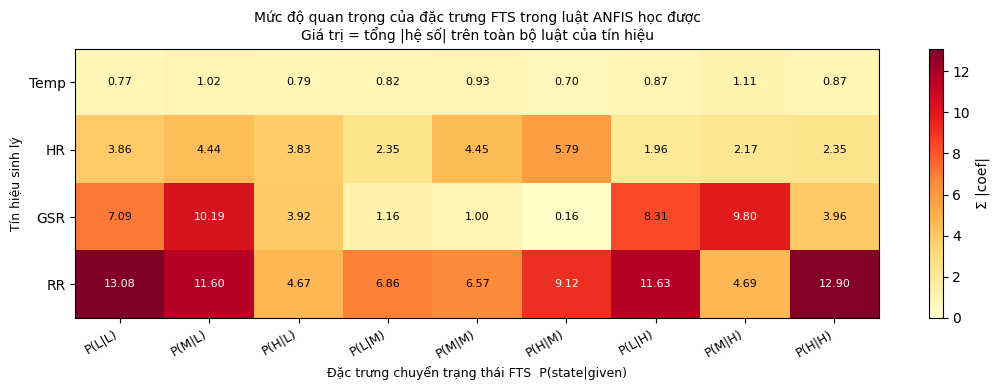

[saved] D:\SGU(1)\official\4-1\KLTN\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_anfis_rule_importance.png


In [17]:
"""
Phần 6: ANFIS Rule Importance Heatmap.
Phân tích các luật TSK học được từ file anfis_rules.json.

Mỗi luật có dạng:
  Ri: IF <feature> is Gauss(c=..., σ=...) AND ... THEN y = coef*<feature> + ...

Tính tổng |coefficient| của mỗi feature trên tất cả rule của signal đó.
Features là các transition probability của FTS: P(L|L), P(M|L), ..., P(H|H)
"""

# Tất cả feature name có thể xuất hiện (FTS 3-set, 9 features)
FEATURE_NAMES = [
    "P(L|L)", "P(M|L)", "P(H|L)",
    "P(L|M)", "P(M|M)", "P(H|M)",
    "P(L|H)", "P(M|H)", "P(H|H)",
]

# ---------------------------------------------------------------
# Parser: trích feature và coefficient từ dòng THEN
# ---------------------------------------------------------------
_coef_re = re.compile(
    r"([+-]?\s*\d+\.\d+)\*P\(([LMH])\|([LMH])\)"
)

def parse_rule_consequent(rule_str: str) -> dict:
    """
    Trích các cặp (feature_name, coefficient) từ phần THEN của rule string.
    Ví dụ: "THEN y = 0.1172*P(M|L) + ..."
    Trả về dict: {'P(M|L)': 0.1172, ...}
    """
    # Lấy phần sau THEN
    if "THEN" not in rule_str:
        return {}
    then_part = rule_str.split("THEN")[1]
    result = {}
    for match in _coef_re.finditer(then_part):
        coef_str, state, given = match.groups()
        coef = float(coef_str.replace(" ", ""))
        feat = f"P({state}|{given})"
        # Tổng hợp nếu feature xuất hiện nhiều lần trong rule
        result[feat] = result.get(feat, 0.0) + coef
    return result

# ---------------------------------------------------------------
# Tính importance matrix (signal x feature)
# ---------------------------------------------------------------
importance = {}
for sig in signals:
    if sig not in anfis_rules:
        importance[sig] = {f: 0.0 for f in FEATURE_NAMES}
        continue
    sig_importance = {f: 0.0 for f in FEATURE_NAMES}
    for rule_str in anfis_rules[sig]:
        coefs = parse_rule_consequent(rule_str)
        for feat, coef in coefs.items():
            if feat in sig_importance:
                sig_importance[feat] += abs(coef)   # tổng |coefficient|
    importance[sig] = sig_importance

df_imp = pd.DataFrame(importance, index=FEATURE_NAMES).T   # (signals x features)
df_imp.index.name = "Signal"
df_imp.columns.name = "FTS_feature"

print("ANFIS feature importance (sum |coef|):")
print(df_imp.round(4))

# Lưu CSV
csv_imp = FIG_DIR / "anfis_rule_importance.csv"
df_imp.to_csv(csv_imp)
print(f"[saved] {csv_imp}")

# ---------------------------------------------------------------
# Vẽ heatmap importance
# ---------------------------------------------------------------
mat_imp = df_imp.values.astype(float)  # (4, 9)
vmax_imp = mat_imp.max() if mat_imp.max() > 0 else 1.0

fig, ax = plt.subplots(figsize=(11, 4))
im2 = ax.imshow(mat_imp, cmap="YlOrRd", vmin=0, vmax=vmax_imp, aspect="auto")

ax.set_xticks(range(len(FEATURE_NAMES)))
ax.set_xticklabels(FEATURE_NAMES, fontsize=9, rotation=30, ha="right")
ax.set_yticks(range(len(signals)))
ax.set_yticklabels(signals, fontsize=10)
ax.set_xlabel("Đặc trưng chuyển trạng thái FTS  P(state|given)", fontsize=9)
ax.set_ylabel("Tín hiệu sinh lý", fontsize=9)
ax.set_title(
    "Mức độ quan trọng của đặc trưng FTS trong luật ANFIS học được\n"
    "Giá trị = tổng |hệ số| trên toàn bộ luật của tín hiệu",
    fontsize=10
)

# Annotate
for i in range(mat_imp.shape[0]):
    for j in range(mat_imp.shape[1]):
        val = mat_imp[i, j]
        color = "white" if val > 0.65 * vmax_imp else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                fontsize=8, color=color)

plt.colorbar(im2, ax=ax, label="Σ |coef|")
fig.tight_layout()
out_path = FIG_DIR / "fig_anfis_rule_importance.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {out_path}")

---
## Phần 7 — Figure captions (đề xuất cho khóa luận)

| Hình | Caption tiếng Việt |
|------|-------------------|
| Hình 4.x | **Cấu trúc Bayesian Network Fusion trong thực nghiệm 1.** Nút gốc CL đại diện cho nhãn tải nhận thức (cognitive load) với hai trạng thái: *rest* và *task*. Bốn nút evidence (Temp, HR, GSR, RR) là các tín hiệu sinh lý được rời rạc hóa thành 5 bin theo phân vị. Xác suất tiên nghiệm P(rest) ≈ P(task) ≈ 0.5 cho thấy dữ liệu gần cân bằng lớp. |
| Hình 4.x | **Mức độ ủng hộ lớp task/rest của từng evidence bin thông qua log-likelihood ratio từ CPT.** Giá trị LLR(s,b) = log P(b\|task) − log P(b\|rest) dương (đỏ) biểu thị bin b ủng hộ trạng thái *task*; âm (xanh) biểu thị ủng hộ *rest*. RR và HR cho thấy xu hướng rõ rệt nhất: bin *very_high* ủng hộ mạnh *task* trong khi *very_low* ủng hộ *rest*. |
| Hình 4.x | **Phân phối CPT thô P(bin\|class) cho từng tín hiệu.** Mỗi biểu đồ grouped bar cho thấy xác suất của từng bin với hai lớp REST và TASK. Sự chênh lệch giữa hai cột trong cùng bin phản ánh độ phân biệt của tín hiệu đó. |
| Hình 4.x | **Truy vết suy luận Bayesian trên một mẫu kiểm thử.** Mỗi thanh thể hiện đóng góp log-likelihood của tín hiệu tương ứng vào quyết định phân lớp. Thanh màu đỏ (dương) ủng hộ *task*, thanh xanh (âm) ủng hộ *rest*. Posterior cuối cùng vượt ngưỡng threshold, cho kết quả dự đoán đúng lớp. |
| Hình 4.x | **Mức độ quan trọng của các đặc trưng chuyển trạng thái FTS trong các luật ANFIS học được.** Giá trị trong mỗi ô là tổng trị tuyệt đối của hệ số TSK tương ứng trên toàn bộ luật của tín hiệu đó. Các đặc trưng có giá trị cao (màu đậm) đóng vai trò chính trong việc phân biệt tải nhận thức thông qua ANFIS. |

---
## Tổng kết — Danh sách file đã lưu

In [18]:
"""
Phần cuối: In danh sách tất cả file đã lưu trong figures_4_2/
"""
print("=" * 60)
print("Danh sách file đã tạo trong", FIG_DIR)
print("=" * 60)
saved_files = sorted(FIG_DIR.glob("*"))
for f in saved_files:
    size_kb = f.stat().st_size / 1024
    print(f"  {f.name:<45}  {size_kb:>7.1f} KB")

Danh sách file đã tạo trong D:\SGU(1)\official\4-1\KLTN\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2
  anfis_rule_importance.csv                          0.5 KB
  cpt_log_likelihood_ratio.csv                       0.5 KB
  fig_anfis_rule_importance.png                    177.4 KB
  fig_bn_structure.png                             149.4 KB
  fig_cpt_GSR.png                                   85.4 KB
  fig_cpt_HR.png                                    86.4 KB
  fig_cpt_llr_heatmap.png                          131.6 KB
  fig_cpt_RR.png                                    89.6 KB
  fig_cpt_Temp.png                                  81.0 KB
  fig_sample_bayesian_prediction.png               131.4 KB
  sample_bn_inference_trace.csv                      0.6 KB


In [19]:
%run main.py --ablation exp3 --preset A2_soft

Exception: File `'main.py'` not found.

In [ ]:
%run main.py --ablation exp4 --preset A2_soft